# 16 偏导数(Partial Derivative)

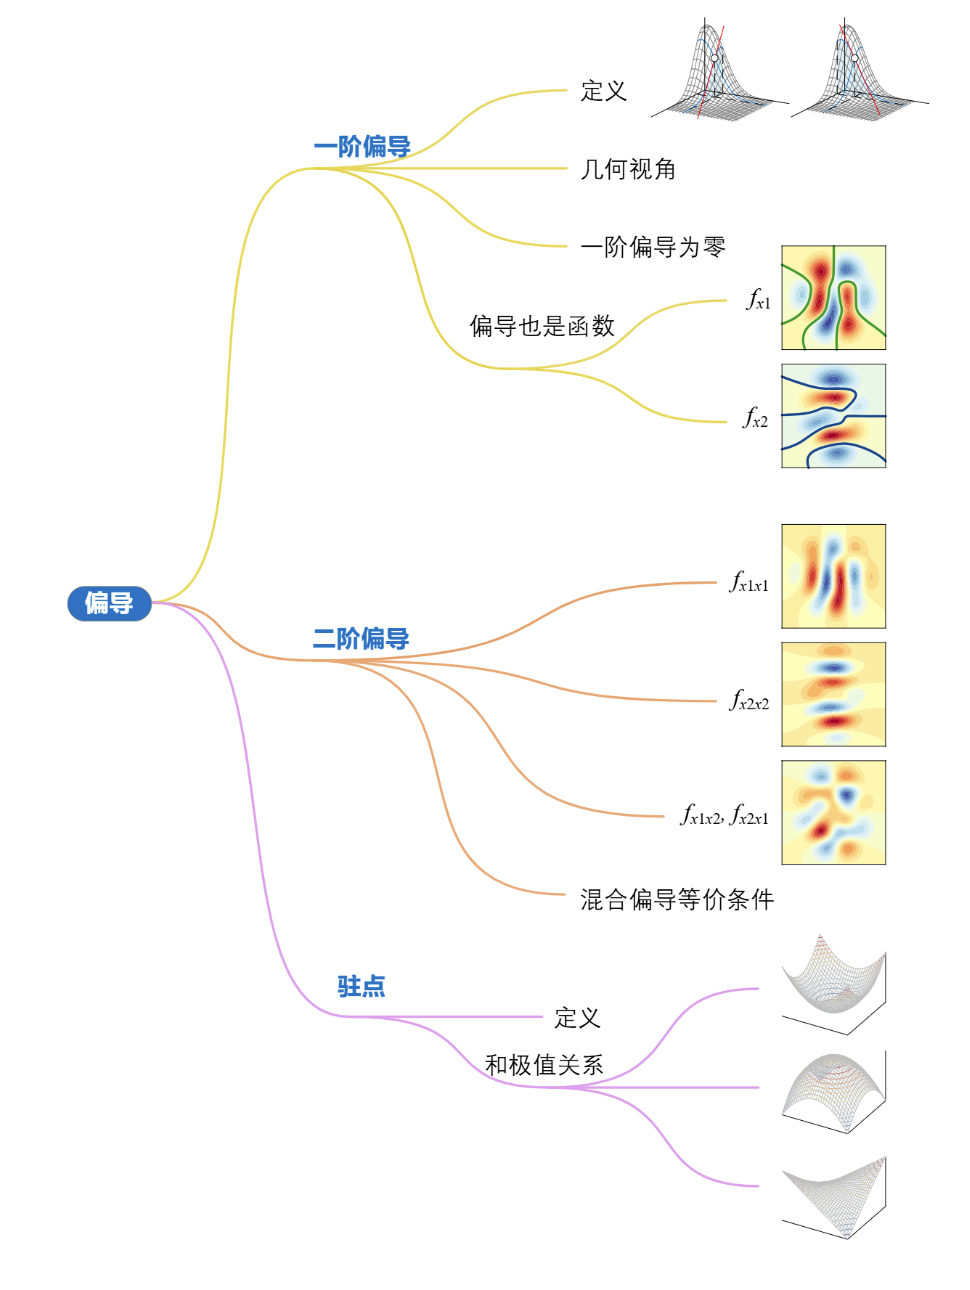

## 16.1 几何角度看偏导数

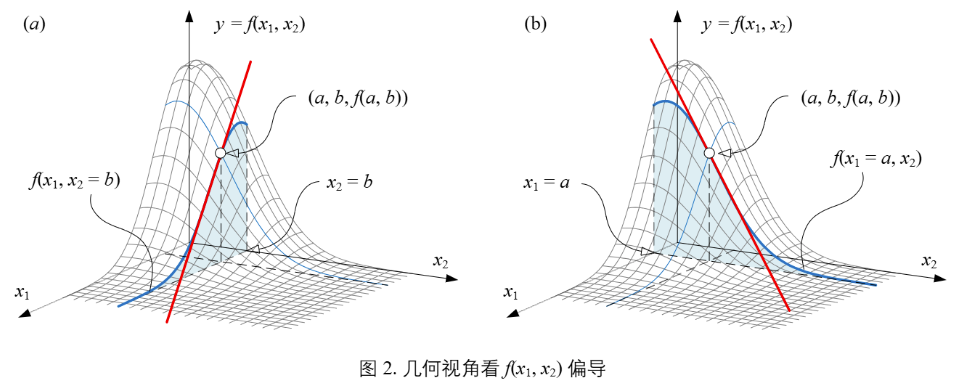

把 $x_2$ 固定在 $b$，即 $x_2=b$，切线斜率代表二元函数 $f(x_1,x_2)$ 在 $(a,b)$ 处沿着 $x_1$ 的变化率。把 $x_1$ 固定在 $a$，即 $x_1=a$，切线斜率代表二元函数 $f(x_1,x_2)$ 在 $(a,b)$ 处沿着 $x_2$ 的变化率。<font color="blue">偏导数</font>(partial derivative)正是研究这种二元乃至多元函数变化率的工具。

### 偏导数定义

将 $x_2$ 固定在 $x_2=b$，$f(x_1,x_2)$ 则变成一个关于 $x_1$ 的一元函数 $f(x_1,b)$。$f(x_1,b)$ 在 $x_1=a$ 处关于 $x_1$ 可导，则称 $f(x_1,x_2)$ 在点 $(a,b)$ 处关于 $x_1$ <font color="blue">可偏微分</font>(partially differentiable)。
    
用极限，$f(x_1,x_2)$ 在点 $(a,b)$ 处关于 $x_1$ 的偏导定义为:
$$
f_{x_1}(a,b)=\left. \frac{\partial f}{\partial x_1}\right|_{\substack{x_1=a\\x_2=b}}
=\lim_{\Delta x_1 \to 0}
\frac{f\left(a+\Delta x_1,{b}\right)-
f\left(a,{b}\right)}{\Delta x_1}
$$

类似地，$f(x_1,x2)$ 在 $(a,b)$ 点对于 $x_2$ 的偏导可以定义为:
$$
f_{x_2}(a,b)=\left. \frac{\partial f}{\partial x_2}\right|_{\substack{x_1=a\\x_2=b}}
=\lim_{\Delta x_2 \to 0}
\frac{f\left(a,b+\Delta x_2\right)-
f\left(a,{b}\right)}{\Delta x_2}
$$

### 一个多极值曲面

In [1]:
import numpy as np
from sympy import lambdify, diff, exp, latex
from sympy.abc import x, y
import matplotlib.pyplot as plt

In [2]:
# 定义网格和函数
num = 301
x_array = np.linspace(-3, 3, num)
y_array = np.linspace(-3, 3, num)
xx, yy = np.meshgrid(x_array, y_array)

$$
f(x_1,x_2)=3(1-x_1)^2\exp\!\left(-x_1^2-(x_2+1)^2\right)
-10\left(\frac{x_1}{5}-x_1^3-x_2^5\right)
\exp\!\left(-x_1^2-x_2^2\right)
-\frac{1}{3}\exp\!\left(-(x_1+1)^2-x_2^2\right)
\tag{3}
$$

In [3]:
f_xy = 3 * (1 - x) ** 2 * exp(-x ** 2 - (y + 1) ** 2) \
       - 10 * (x / 5 - x ** 3 - y ** 5) * exp(-x ** 2 - y ** 2)\
       - 1 / 3 * exp(-(x + 1) ** 2 - y ** 2)
f_xy

3*(1 - x)**2*exp(-x**2 - (y + 1)**2) - (-10*x**3 + 2*x - 10*y**5)*exp(-x**2 - y**2) - 0.333333333333333*exp(-y**2 - (x + 1)**2)

In [43]:
f_xy_fcn = lambdify([x, y], f_xy)
f_xy_zz = f_xy_fcn(xx, yy)

### 对 $x_1$ 偏导

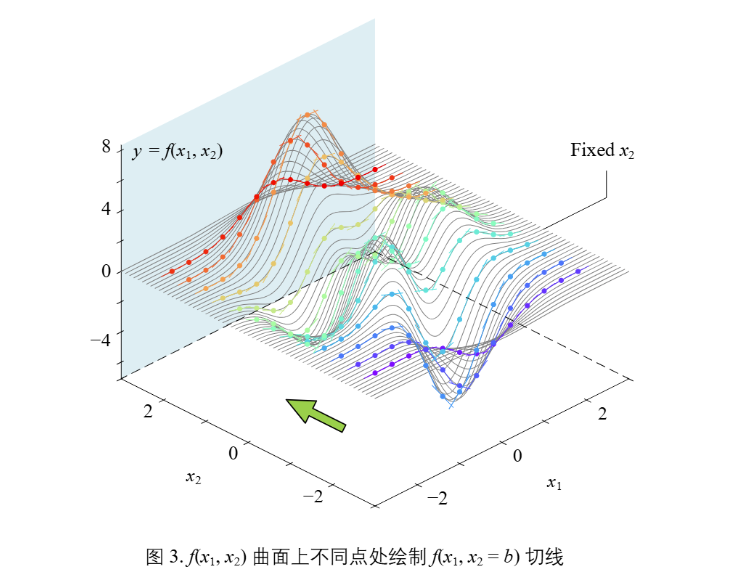
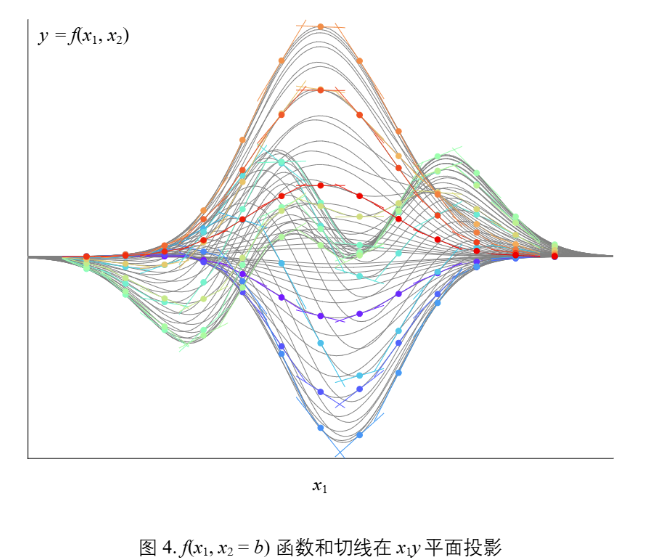

### 对 $x_2$ 偏导

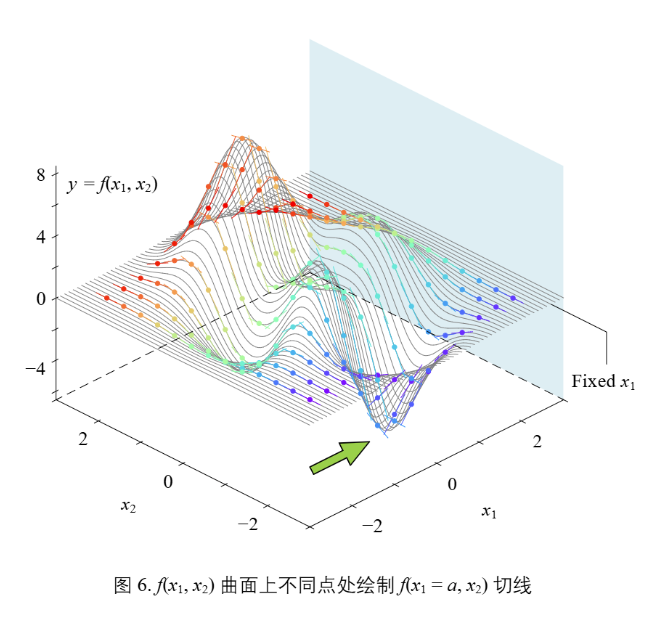
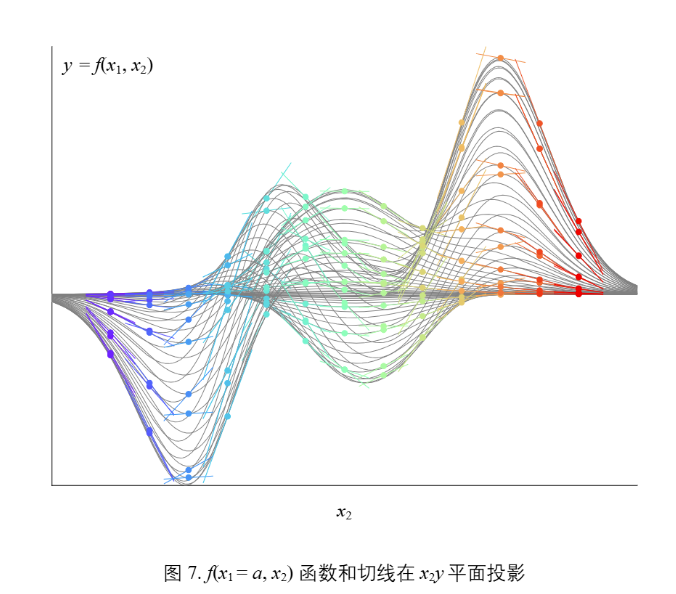

## 16.2 偏导也是函数

### 对 $x_1$ 偏导 

In [17]:
# 对 x 的一阶偏导数
df_dx = f_xy.diff(x)
df_dx

-6*x*(1 - x)**2*exp(-x**2 - (y + 1)**2) + 2*x*(-10*x**3 + 2*x - 10*y**5)*exp(-x**2 - y**2) - (2 - 30*x**2)*exp(-x**2 - y**2) - 0.333333333333333*(-2*x - 2)*exp(-y**2 - (x + 1)**2) + 3*(2*x - 2)*exp(-x**2 - (y + 1)**2)

In [6]:
df_dx_fcn = lambdify([x, y], df_dx)
df_dx_zz = df_dx_fcn(xx, yy)

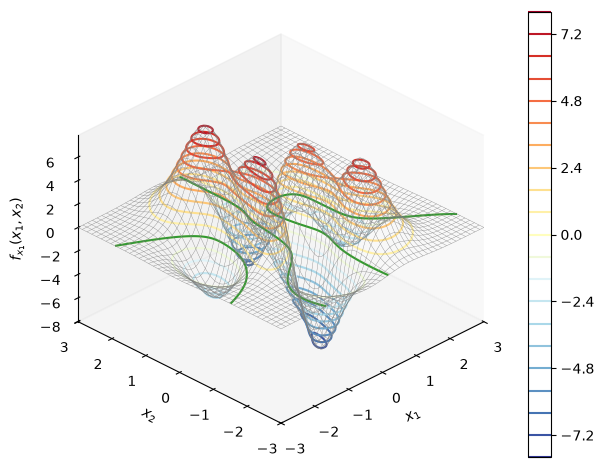

In [22]:
# 绘制对 x 的一阶偏导数的 3D 图像
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})

ax.plot_wireframe(xx, yy, df_dx_zz, color=[0.5, 0.5, 0.5], linewidth = 0.25)
colorbar = ax.contour(xx, yy, df_dx_zz, 20, cmap="RdYlBu_r")   # 绘制等高线并着色

ax.contour(xx, yy, df_dx_zz, levels=[0], colors="#339933", linestyle="-") # 添加绿色等高线，表示 df/dx = 0 的区域

fig.colorbar(colorbar, ax=ax)
ax.set_proj_type("ortho")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$f_{x_1}(x_1, x_2)$")
plt.tight_layout()
ax.set_xlim(xx.min(), xx.max())
ax.set_ylim(yy.min(), yy.max())
ax.view_init(azim=-135, elev=30)
ax.grid(False)
plt.show()

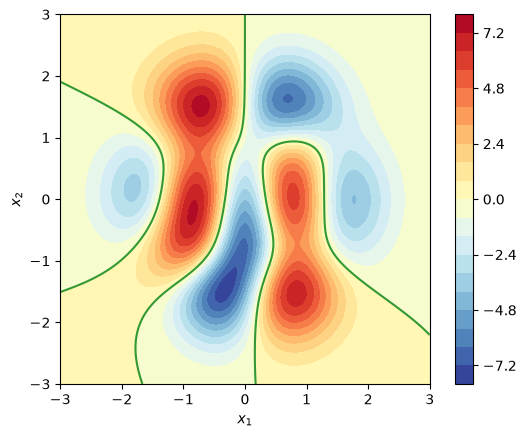

In [23]:
# 绘制对 x 的一阶偏导数的等高线图
fig, ax = plt.subplots()

colorbar = ax.contourf(xx, yy, df_dx_zz, 20, cmap="RdYlBu_r")
ax.contour(xx, yy, df_dx_zz, levels=[0], colors="#339933", linestyle="-")

fig.colorbar(colorbar, ax=ax)
ax.set_xlim(xx.min(), xx.max())
ax.set_ylim(yy.min(), yy.max())
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
plt.gca().set_aspect("equal", adjustable="box")
plt.show()

### 对 $x_2$ 偏导

In [20]:
# 对 y 的一阶偏导数
df_dy = f_xy.diff(y)
df_dy

50*y**4*exp(-x**2 - y**2) + 2*y*(-10*x**3 + 2*x - 10*y**5)*exp(-x**2 - y**2) + 0.666666666666667*y*exp(-y**2 - (x + 1)**2) + 3*(1 - x)**2*(-2*y - 2)*exp(-x**2 - (y + 1)**2)

In [21]:
df_dy_fcn = lambdify([x, y], df_dy)
df_dy_zz = df_dy_fcn(xx, yy)

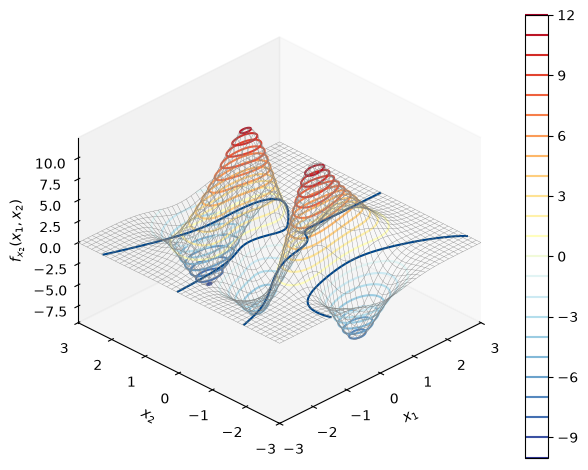

In [24]:
# 绘制对 y 的一阶偏导数的 3D 图像
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})

ax.plot_wireframe(xx, yy, df_dy_zz, color=[0.5, 0.5, 0.5], linewidth = 0.25)
colorbar = ax.contour(xx, yy, df_dy_zz, 20, cmap="RdYlBu_r")   # 绘制等高线并着色

ax.contour(xx, yy, df_dy_zz, levels=[0], colors="#00448A", linestyle="-") # 添加绿色等高线，表示 df/dx = 0 的区域

fig.colorbar(colorbar, ax=ax)
ax.set_proj_type("ortho")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$f_{x_2}(x_1, x_2)$")
plt.tight_layout()
ax.set_xlim(xx.min(), xx.max())
ax.set_ylim(yy.min(), yy.max())
ax.view_init(azim=-135, elev=30)
ax.grid(False)
plt.show()

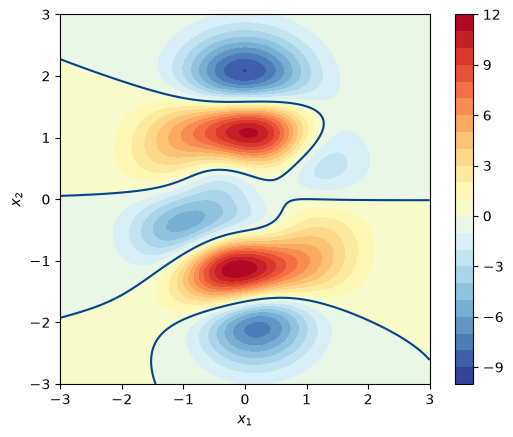

In [26]:
# 绘制对 y 的一阶偏导数的等高线图
fig, ax = plt.subplots()

colorbar = ax.contourf(xx, yy, df_dy_zz, 20, cmap="RdYlBu_r")
ax.contour(xx, yy, df_dy_zz, levels=[0], colors="#00448A", linestyle="-")

fig.colorbar(colorbar, ax=ax)
ax.set_xlim(xx.min(), xx.max())
ax.set_ylim(yy.min(), yy.max())
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
plt.gca().set_aspect("equal", adjustable="box")
plt.show()

## 16.3 二阶偏导函数的一阶偏导

In [35]:
def plot_surface(xx, yy, surface, title_txt):
    fig = plt.figure(figsize=plt.figaspect(0.5))
    ax = fig.add_subplot(1, 2, 1, projection="3d")
    ax.plot_wireframe(xx, yy, surface, color=[0.5, 0.5, 0.5], linewidth=0.25)
    colorbar = ax.contour(xx, yy, surface, 20, cmap="RdYlBu_r")

    ax.set_proj_type("ortho")
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_zlabel(title_txt)
    ax.set_xlim(xx.min(), xx.max())
    ax.set_ylim(yy.min(), yy.max())
    ax.view_init(azim=-135, elev=30)
    ax.grid(False)

    ax = fig.add_subplot(1, 2, 2)
    colorbar = ax.contourf(xx, yy, surface, 20, cmap="RdYlBu_r")
    ax.set_xlim(xx.min(), xx.max())
    ax.set_ylim(yy.min(), yy.max())
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    plt.gca().set_aspect("equal", adjustable="box")

### 对 $x_1$ 二阶偏导

$f_{x_1}(x_1，x_2)$ 对 $x_1$ 求一阶偏导得到 $f(x_1，x_2)$ 对 $x_1$ 的二阶偏导，记做:
$$
\frac{\partial}{\partial x_1}
\left(\frac{\partial f}{\partial x_1}\right)
=\frac{\partial^2 f}{\partial x_1^2}
=f_{x_1x_1}
=\left(f_{x_1}\right)_{x_1}
$$

In [30]:
d2f_dxdx = f_xy.diff(x, 2)
d2f_dxdx

12*x**2*(x - 1)**2*exp(-x**2 - (y + 1)**2) + 8*x**2*(5*x**3 - x + 5*y**5)*exp(-x**2 - y**2) - 24*x*(x - 1)*exp(-x**2 - (y + 1)**2) - 8*x*(15*x**2 - 1)*exp(-x**2 - y**2) + 60*x*exp(-x**2 - y**2) - 6*(x - 1)**2*exp(-x**2 - (y + 1)**2) - 1.33333333333333*(x + 1)**2*exp(-y**2 - (x + 1)**2) - 4*(5*x**3 - x + 5*y**5)*exp(-x**2 - y**2) + 6*exp(-x**2 - (y + 1)**2) + 0.666666666666667*exp(-y**2 - (x + 1)**2)

In [31]:
d2f_dxdx_fcn = lambdify([x, y], d2f_dxdx)
d2f_dxdx_zz = d2f_dxdx_fcn(xx, yy)

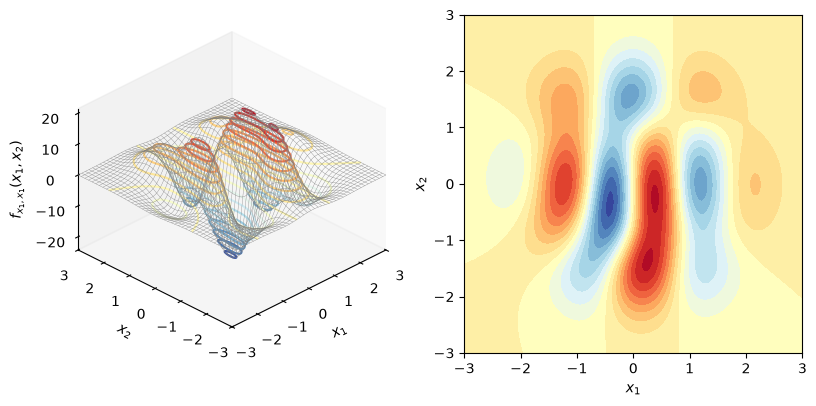

In [36]:
title_txt = "$f_{x_1, x_1}(x_1, x_2)$"
plot_surface(xx, yy, d2f_dxdx_zz, title_txt)

### 对 $x_2$ 二阶求导

$f_{x_2}(x_1，x_2)$ 对 $x_2$ 求一阶偏导得到 $f(x_1，x_2)$ 对 $x_2$ 的二阶偏导:
$$
\frac{\partial}{\partial x_2}
\left(\frac{\partial f}{\partial x_2}\right)
=\frac{\partial^2 f}{\partial x_2^2}
=f_{x_2x_2}
=\left(f_{x_2}\right)_{x_2}
$$

In [37]:
d2f_dydy = f_xy.diff(y, 2)
d2f_dydy

-200*y**5*exp(-x**2 - y**2) + 200*y**3*exp(-x**2 - y**2) + 8*y**2*(5*x**3 - x + 5*y**5)*exp(-x**2 - y**2) - 1.33333333333333*y**2*exp(-y**2 - (x + 1)**2) + 12*(x - 1)**2*(y + 1)**2*exp(-x**2 - (y + 1)**2) - 6*(x - 1)**2*exp(-x**2 - (y + 1)**2) - 4*(5*x**3 - x + 5*y**5)*exp(-x**2 - y**2) + 0.666666666666667*exp(-y**2 - (x + 1)**2)

In [38]:
d2f_dydy_fcn = lambdify([x, y], d2f_dydy)
d2f_dydy_zz = d2f_dydy_fcn(xx, yy)

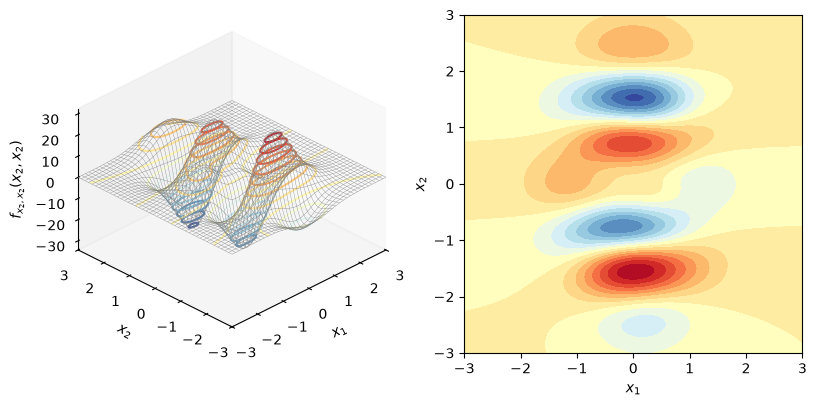

In [39]:
title_txt = "$f_{x_2, x_2}(x_2, x_2)$"
plot_surface(xx, yy, d2f_dydy_zz, title_txt)

### 二阶混合偏导

$f_{x_1}(x_1,x_2)$ 对 $x_2$ 求一阶偏导得到 $f(x_1,x_2)$ 先对 $x_1$、后对 $x_2$ 二阶混合偏导，记做:
$$
\frac{\partial}{\partial x_2}
\left(\frac{\partial f}{\partial x_1}\right)
=\frac{\partial^2 f}{\partial x_1\partial x_2}
=f_{x_1x_2}
=\left(f_{x_1}\right)_{x_2}
$$

$f_{x_2}(x1,x2)$ 对 $x1$ 求一阶偏导得到 $f(x1,x2)$ 先对 $x_2$、后对 $x_1$ 二阶混合偏导:

$$
\frac{\partial}{\partial x_1}
\left(\frac{\partial f}{\partial x_2}\right)
=\frac{\partial^2 f}{\partial x_2\partial x_1}
=f_{x_2x_1}
=\left(f_{x_2}\right)_{x_1}
$$

In [40]:
d2f_dxdy = f_xy.diff(x, y)
d2f_dxdy

-100*x*y**4*exp(-x**2 - y**2) + 8*x*y*(5*x**3 - x + 5*y**5)*exp(-x**2 - y**2) + 12*x*(x - 1)**2*(y + 1)*exp(-x**2 - (y + 1)**2) - 1.33333333333333*y*(x + 1)*exp(-y**2 - (x + 1)**2) - 4*y*(15*x**2 - 1)*exp(-x**2 - y**2) - 12*(x - 1)*(y + 1)*exp(-x**2 - (y + 1)**2)

In [41]:
d2f_dxdy_fcn = lambdify([x, y], d2f_dxdy)
d2f_dxdy_zz = d2f_dxdy_fcn(xx, yy)

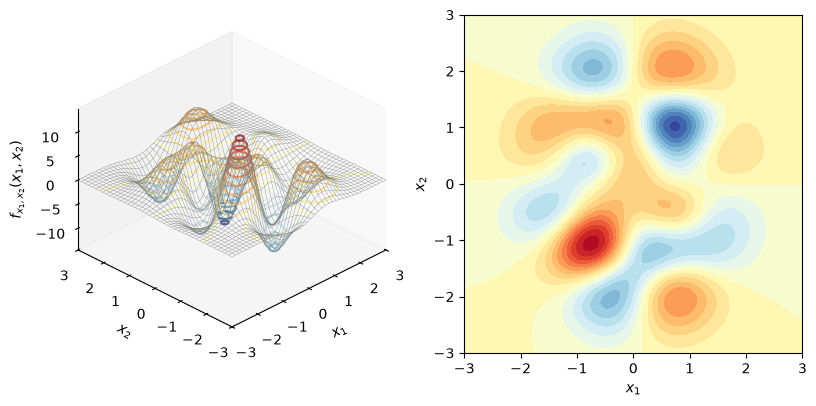

In [42]:
title_txt = "$f_{x_1, x_2}(x_1, x_2)$"
plot_surface(xx, yy, d2f_dxdy_zz, title_txt)

如果函数 $f(x_1，x_2)$ 在某个特定区域内两个二阶混合偏导 $f_{x_2x_1}$、$f_{x_1x_2}$ 连续，那么这两个混合偏导数相等，即:
$$
\frac{\partial^2f}{\partial x_2\partial x_1} = \frac{\partial^2f}{\partial x_1\partial x_2}
$$

### 和杨辉三角的联系

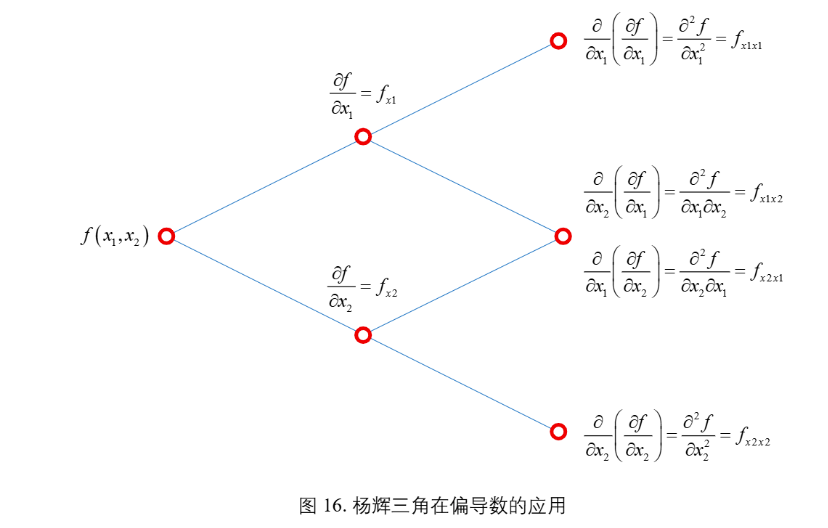

## 16.4 二元曲面的驻点：一阶偏导为 0

### 对 $x_1$ 一阶偏导为0

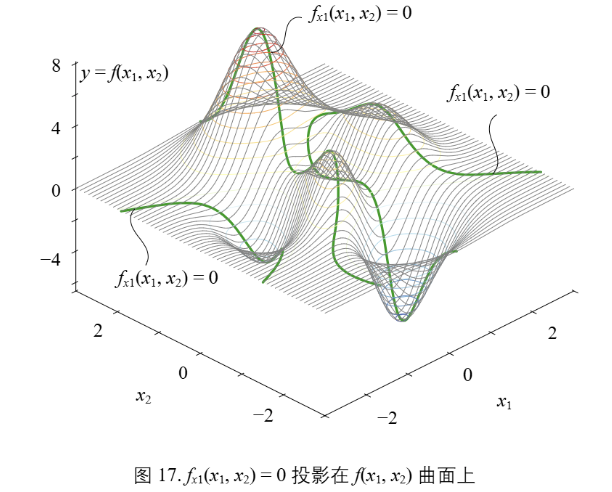

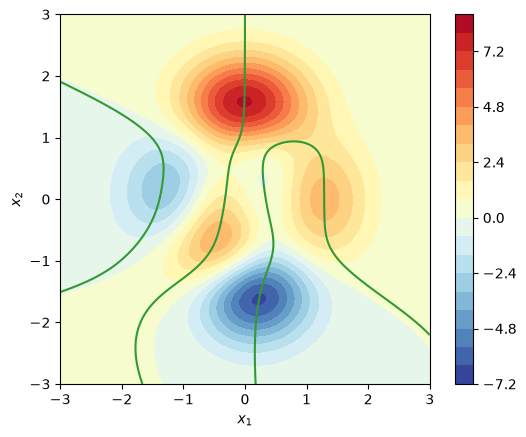

In [44]:
# 绘制函数的等高线图和一阶偏导数的零等高线
fig, ax = plt.subplots()

colorbar = ax.contourf(xx, yy, f_xy_zz, 20, cmap="RdYlBu_r")
fig.colorbar(colorbar, ax=ax)

ax.contour(xx, yy, df_dx_zz, levels=[0], colors="#339933")
ax.set_xlim(xx.min(), xx.max())
ax.set_ylim(yy.min(), yy.max())
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
plt.gca().set_aspect("equal", adjustable="box")
plt.show()

### 对 $x_2$ 一阶偏导为0

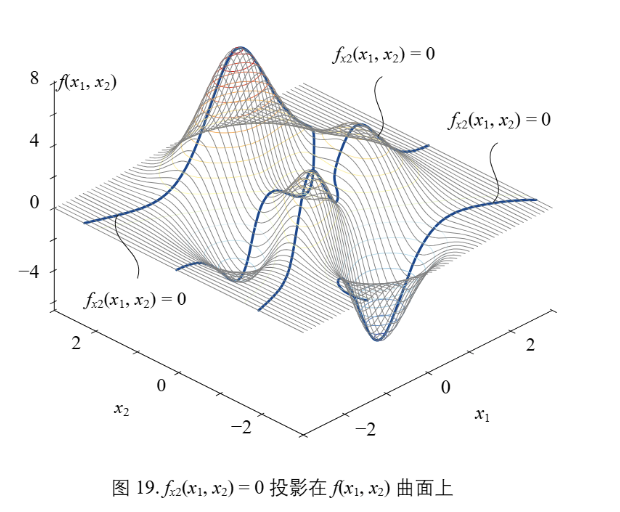

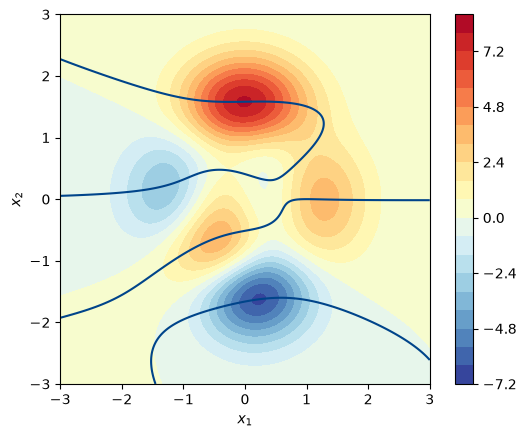

In [46]:
# 绘制函数的等高线图和一阶偏导数的零等高线
fig, ax = plt.subplots()

colorbar = ax.contourf(xx, yy, f_xy_zz, 20, cmap="RdYlBu_r")
fig.colorbar(colorbar, ax=ax)

ax.contour(xx, yy, df_dy_zz, levels=[0], colors="#00448A")
ax.set_xlim(xx.min(), xx.max())
ax.set_ylim(yy.min(), yy.max())
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
plt.gca().set_aspect("equal", adjustable="box")
plt.show()

### 二元函数驻点

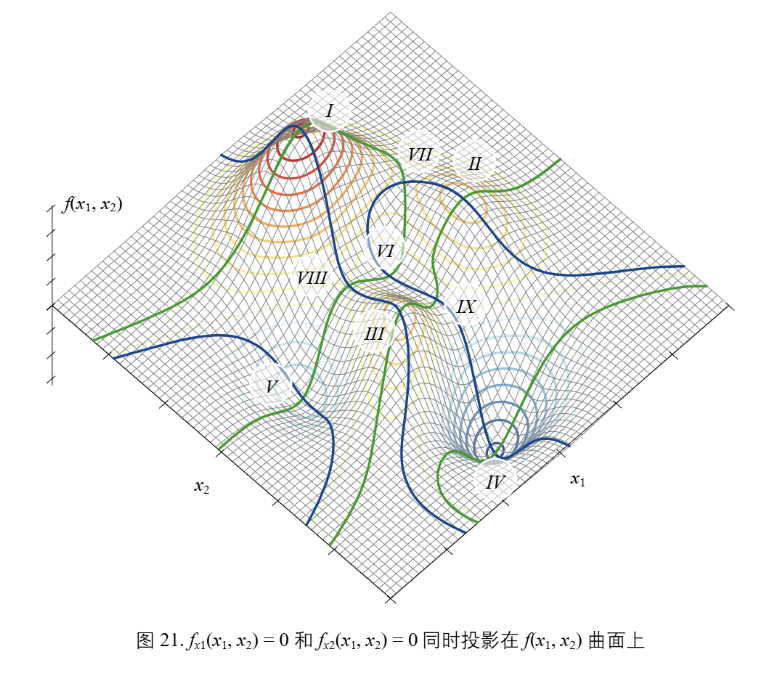

Ⅰ、Ⅱ、Ⅲ 点为极大值点，其中 Ⅰ 为最大值点。、Ⅳ、Ⅴ、Ⅵ 为极小值点，其中 Ⅵ 为最小值点。Ⅶ、Ⅷ、Ⅸ，它们既不是极大值点，也不是极小值点。Ⅶ、Ⅷ、Ⅸ就是所谓的鞍点。

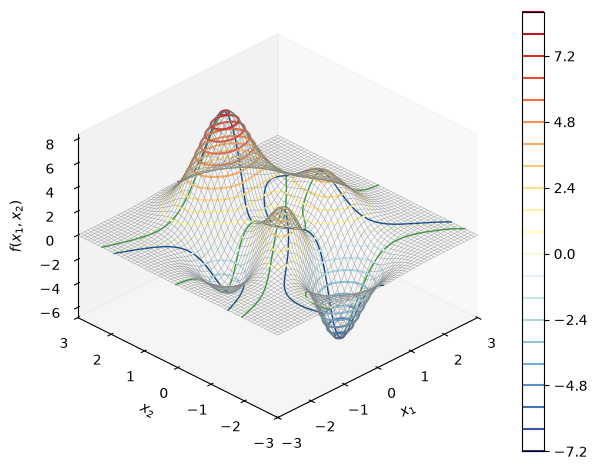

In [53]:
fig, ax = plt.subplots(subplot_kw={"projection":"3d"})

CS_y = ax.contour(xx, yy, df_dy_zz, levels=[0], colors="#339933")
CS_x = ax.contour(xx, yy, df_dx_zz, levels=[0], colors="#339933")
ax.cla() # 清空图像

ax.plot_wireframe(xx, yy, f_xy_zz, color=[0.5, 0.5, 0.5], rstride=5, cstride=5, linewidth=0.25)
colorbar = ax.contour(xx, yy, f_xy_zz, 20, cmap="RdYlBu_r")

fig.colorbar(colorbar, ax=ax)

# 绘制 df/dy = 0 等高线
for i in range(0, len(CS_y.allsegs[0])):
    contour_points_x_y = CS_y.allsegs[0][i]
    contour_points_z = f_xy_fcn(contour_points_x_y[:, 0], contour_points_x_y[:, 1])
    ax.plot3D(contour_points_x_y[:, 0], contour_points_x_y[:, 1], contour_points_z, color="#339933", linewidth=1)

# 绘制 df/dx = 0 等高线
for i in range(0, len(CS_x.allsegs[0])):
    contour_points_x_y = CS_x.allsegs[0][i]
    contour_points_z = f_xy_fcn(contour_points_x_y[:, 0], contour_points_x_y[:, 1])
    ax.plot3D(contour_points_x_y[:, 0], contour_points_x_y[:, 1], contour_points_z, color="#00448A", linewidth=1)

ax.set_proj_type("ortho")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$f(x_1, x_2)$")

ax.set_xlim(xx.min(), xx.max())
ax.set_ylim(yy.min(), yy.max())
ax.view_init(azim=-135, elev=30)
plt.tight_layout()
ax.grid(False)
plt.show()

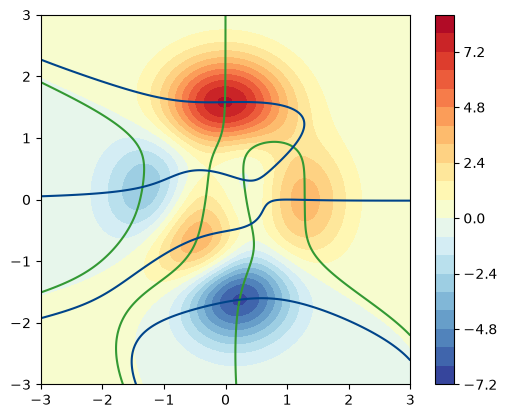

In [54]:
# 绘制驻点等高线的二维图
fig, ax = plt.subplots()

colorbar = ax.contourf(xx, yy, f_xy_zz, 20, cmap="RdYlBu_r")
fig.colorbar(colorbar, ax=ax)

ax.contour(xx, yy, df_dx_zz, levels=[0], colors="#339933", linestyle="-")
ax.contour(xx, yy, df_dy_zz, levels=[0], colors="#00448A", linestyle="-")

ax.set_xlim(xx.min(), xx.max())
ax.set_ylim(yy.min(), yy.max())
ax.set_label("$x_1$")
ax.set_label("$x_2$")
plt.gca().set_aspect("equal", adjustable="box")
plt.show()